# Scalable Sequential Discrimination Algorithm Comparison

This notebook compares Greedy, Heuristic, and Uniform allocation on the expanded 1D and 2D benchmarks. Exhaustive search is intentionally excluded because it is not practical for the larger $K$ and $M$ values.

In [31]:
from pathlib import Path
import importlib
import sys

import matplotlib.pyplot as plt
from IPython.display import Markdown, display

# Find the module folder from the repository root or this folder.
working_directory = Path.cwd().resolve()
MODULE_DIRECTORY = (
    working_directory / "min-error-sequential"
    if (working_directory / "min-error-sequential").is_dir()
    else working_directory
)
if str(MODULE_DIRECTORY) not in sys.path:
    sys.path.insert(0, str(MODULE_DIRECTORY))

import approximate_comparison_analysis as comparison_analysis

# Reload local analysis code when this notebook is already open.
comparison_analysis = importlib.reload(comparison_analysis)
approximate_summary = comparison_analysis.approximate_summary
load_approximate_results = comparison_analysis.load_approximate_results
run_approximate_dataset = comparison_analysis.run_approximate_dataset

## Run settings

Test mode uses four replicates from every field-family, $K$, and $M$ cell, giving 360 cases per dataset. Full mode uses all 2,700 cases per dataset.

In [32]:
# Run the expanded one-dimensional and two-dimensional datasets.
DATASETS = ["benchmark_1d", "benchmark_2d"]

# False runs 360 balanced cases; True runs all 2,700 cases per dataset.
RUN_ALL_REPLICATES = False
REPLICATES_PER_CELL = None if RUN_ALL_REPLICATES else 4
RUN_SCOPE = "full" if RUN_ALL_REPLICATES else "test"
PROGRESS_EVERY = 25

# Keep scalable results separate from the lite exact comparison.
RESULTS_ROOT = MODULE_DIRECTORY / "results" / "algorithm_comparison"

print("Run mode:", "full: 2,700 cases per dataset" if RUN_ALL_REPLICATES else "test: 360 cases per dataset")
print("Replicates per field-family, K, M cell:", REPLICATES_PER_CELL or "all")
print("Results directory:", RESULTS_ROOT)

Run mode: test: 360 cases per dataset
Replicates per field-family, K, M cell: 4
Results directory: /Users/avishka/Academic/PhD/Research/QSN Research/Repos/quantum-sensor-placement-research/min-error-sequential/results/algorithm_comparison


## Algorithm configuration

The heuristic uses beam width $B=3$. The same initialization and random seed are used for every benchmark case.

In [33]:
# Greedy has no optional tuning parameters.
GREEDY_PARAMETERS = {}

# Configure partial-tree beam search and allocation improvement.
HEURISTIC_PARAMETERS = {
    "beam_width": 3,
    "max_iterations": 50,
    "improvement_threshold": 1e-4,
    "initialization": "near_uniform",
    "random_seed": 0,
}

# Reproduce the near-uniform remainder placement.
UNIFORM_PARAMETERS = {"random_seed": 0}

print("Greedy parameters:", GREEDY_PARAMETERS)
print("Heuristic parameters:", HEURISTIC_PARAMETERS)
print("Uniform parameters:", UNIFORM_PARAMETERS)

Greedy parameters: {}
Heuristic parameters: {'beam_width': 3, 'max_iterations': 50, 'improvement_threshold': 0.0001, 'initialization': 'near_uniform', 'random_seed': 0}
Uniform parameters: {'random_seed': 0}


## Run all three algorithms

In [34]:
records_by_dataset = {}
for dataset in DATASETS:
    display(Markdown(f"### Running `{dataset}`"))
    records_by_dataset[dataset] = run_approximate_dataset(
        dataset,
        replicates_per_cell=REPLICATES_PER_CELL,
        results_root=RESULTS_ROOT,
        greedy_parameters=GREEDY_PARAMETERS,
        heuristic_parameters=HEURISTIC_PARAMETERS,
        uniform_parameters=UNIFORM_PARAMETERS,
        progress_every=PROGRESS_EVERY,
    )

### Running `benchmark_1d`

benchmark_1d: completed case 1/360 (gaussian, K=3, M=3)
benchmark_1d: completed case 25/360 (gaussian, K=4, M=3)
benchmark_1d: completed case 50/360 (gaussian, K=5, M=3)
benchmark_1d: completed case 75/360 (gaussian, K=6, M=3)
benchmark_1d: completed case 100/360 (gaussian, K=7, M=3)
benchmark_1d: completed case 125/360 (sinusoidal, K=3, M=4)
benchmark_1d: completed case 150/360 (sinusoidal, K=4, M=4)
benchmark_1d: completed case 175/360 (sinusoidal, K=5, M=4)
benchmark_1d: completed case 200/360 (sinusoidal, K=6, M=4)
benchmark_1d: completed case 225/360 (sinusoidal, K=7, M=5)
benchmark_1d: completed case 250/360 (quadratic, K=3, M=5)
benchmark_1d: completed case 275/360 (quadratic, K=4, M=5)
benchmark_1d: completed case 300/360 (quadratic, K=5, M=5)
benchmark_1d: completed case 325/360 (quadratic, K=6, M=6)
benchmark_1d: completed case 350/360 (quadratic, K=7, M=6)
benchmark_1d: completed case 360/360 (quadratic, K=7, M=8)


### Running `benchmark_2d`

benchmark_2d: completed case 1/360 (gaussian, K=3, M=3)
benchmark_2d: completed case 25/360 (gaussian, K=4, M=3)
benchmark_2d: completed case 50/360 (gaussian, K=5, M=3)
benchmark_2d: completed case 75/360 (gaussian, K=6, M=3)
benchmark_2d: completed case 100/360 (gaussian, K=7, M=3)
benchmark_2d: completed case 125/360 (sinusoidal, K=3, M=4)
benchmark_2d: completed case 150/360 (sinusoidal, K=4, M=4)
benchmark_2d: completed case 175/360 (sinusoidal, K=5, M=4)
benchmark_2d: completed case 200/360 (sinusoidal, K=6, M=4)
benchmark_2d: completed case 225/360 (sinusoidal, K=7, M=5)
benchmark_2d: completed case 250/360 (quadratic, K=3, M=5)
benchmark_2d: completed case 275/360 (quadratic, K=4, M=5)
benchmark_2d: completed case 300/360 (quadratic, K=5, M=5)
benchmark_2d: completed case 325/360 (quadratic, K=6, M=6)
benchmark_2d: completed case 350/360 (quadratic, K=7, M=6)
benchmark_2d: completed case 360/360 (quadratic, K=7, M=8)


## Numerical summary

In [35]:
# Load saved records when the expensive run cell was intentionally skipped.
if "records_by_dataset" not in globals():
    records_by_dataset = {
        dataset: load_approximate_results(
            dataset, results_root=RESULTS_ROOT, run_scope=RUN_SCOPE
        )
        for dataset in DATASETS
    }

summary_lines = [
    "| Dataset | Algorithm | Cases | Budget runs | Mean error | Maximum error | Mean runtime (s) | Median runtime (s) |",
    "|---|---|---:|---:|---:|---:|---:|---:|",
]
for dataset, records in records_by_dataset.items():
    for row in approximate_summary(records):
        summary_lines.append(
            f"| {dataset} | {row['algorithm']} | {row['cases']} | {row['runs']} | "
            f"{row['mean_error']:.5f} | {row['maximum_error']:.5f} | "
            f"{row['mean_seconds']:.5f} | {row['median_seconds']:.5f} |"
        )
display(Markdown("\n".join(summary_lines)))

| Dataset | Algorithm | Cases | Budget runs | Mean error | Maximum error | Mean runtime (s) | Median runtime (s) |
|---|---|---:|---:|---:|---:|---:|---:|
| benchmark_1d | Greedy | 360 | 1429 | 0.35993 | 0.79299 | 0.00397 | 0.00215 |
| benchmark_1d | Heuristic | 360 | 1429 | 0.32041 | 0.76081 | 0.05232 | 0.01007 |
| benchmark_1d | Uniform | 360 | 1429 | 0.55450 | 0.84519 | 0.00019 | 0.00015 |
| benchmark_2d | Greedy | 360 | 1433 | 0.39091 | 0.83513 | 0.00389 | 0.00215 |
| benchmark_2d | Heuristic | 360 | 1433 | 0.34632 | 0.81067 | 0.05014 | 0.01029 |
| benchmark_2d | Uniform | 360 | 1433 | 0.57365 | 0.85073 | 0.00018 | 0.00014 |

## Comparison plots

The detailed mean-error figure retains separate panels for each $K$. A second summarized figure shows only 1D and 2D panels, averaged across all included $K$, $M$, and field families. Both use solid lines without confidence intervals. The runtime and field-family figures retain vertical boxplots and use the same algorithm colors.

### Mean error curves

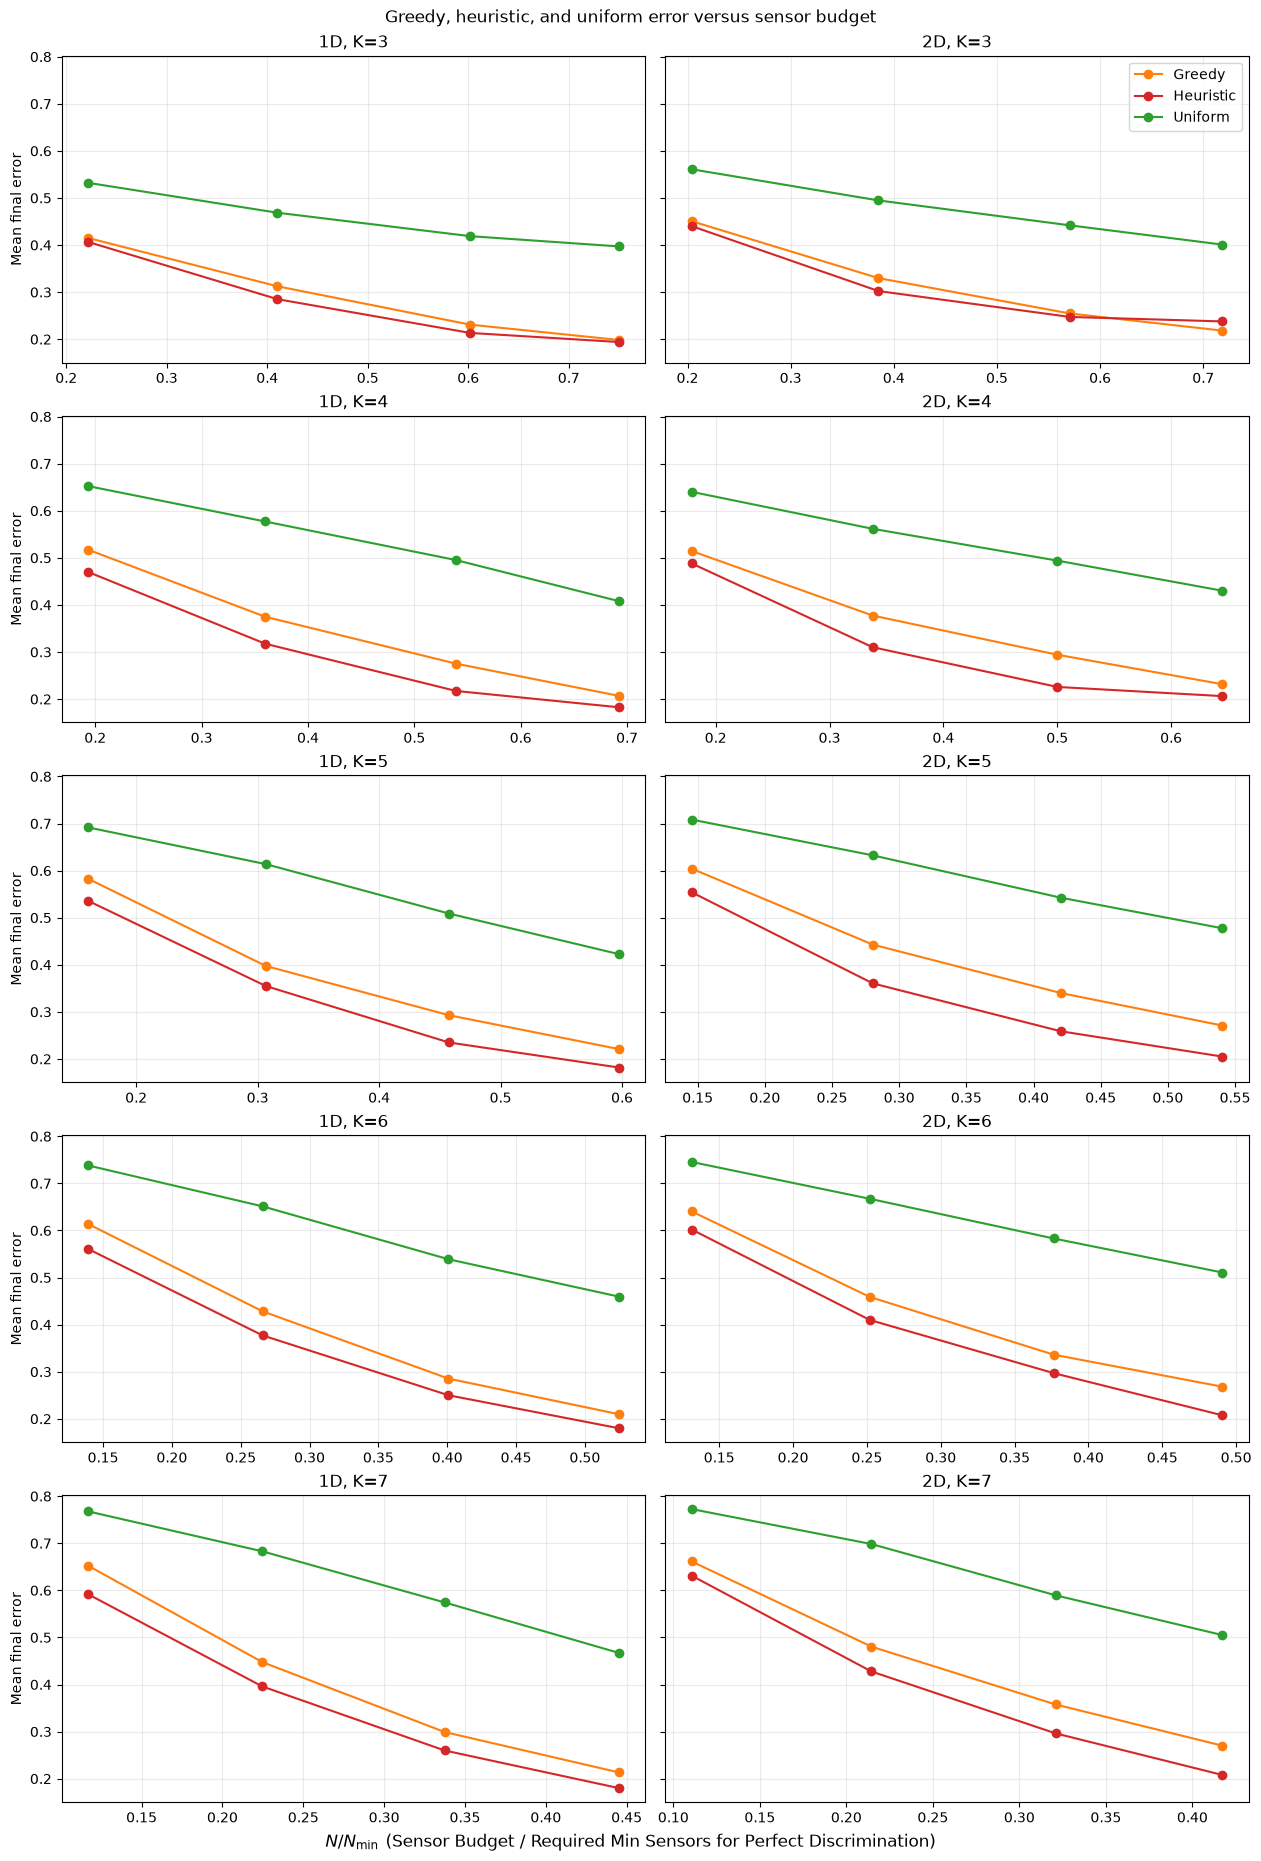

### Overall mean error curves

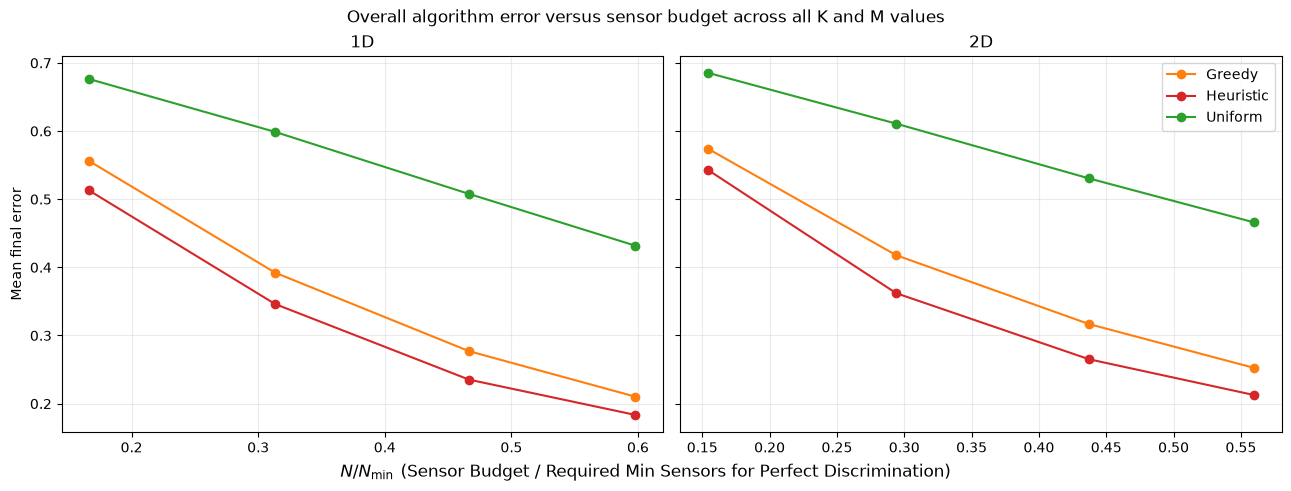

### Runtime distribution by K

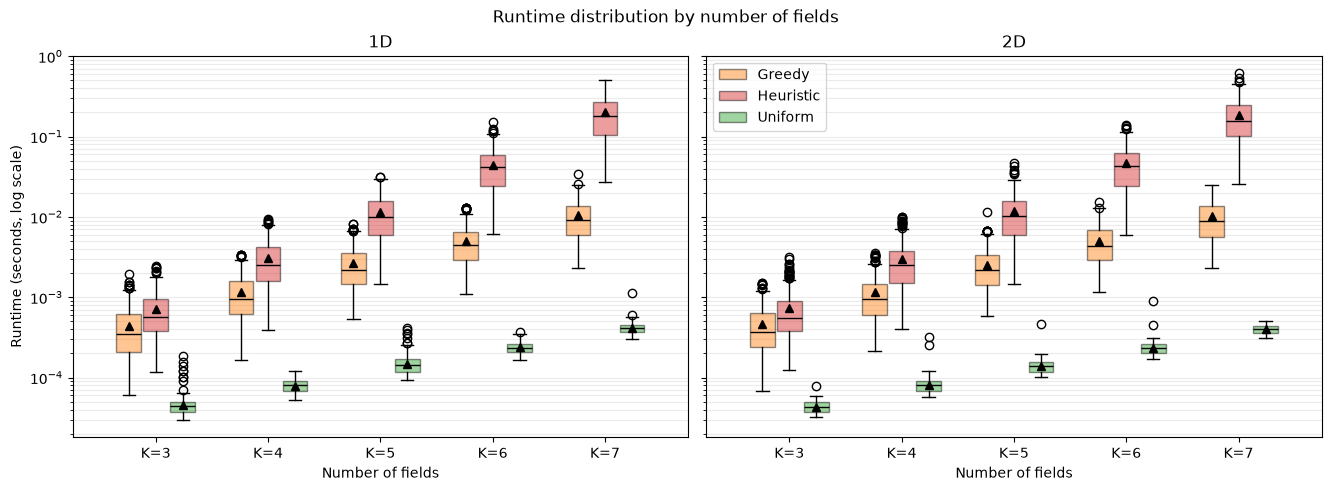

### Error distribution by field family

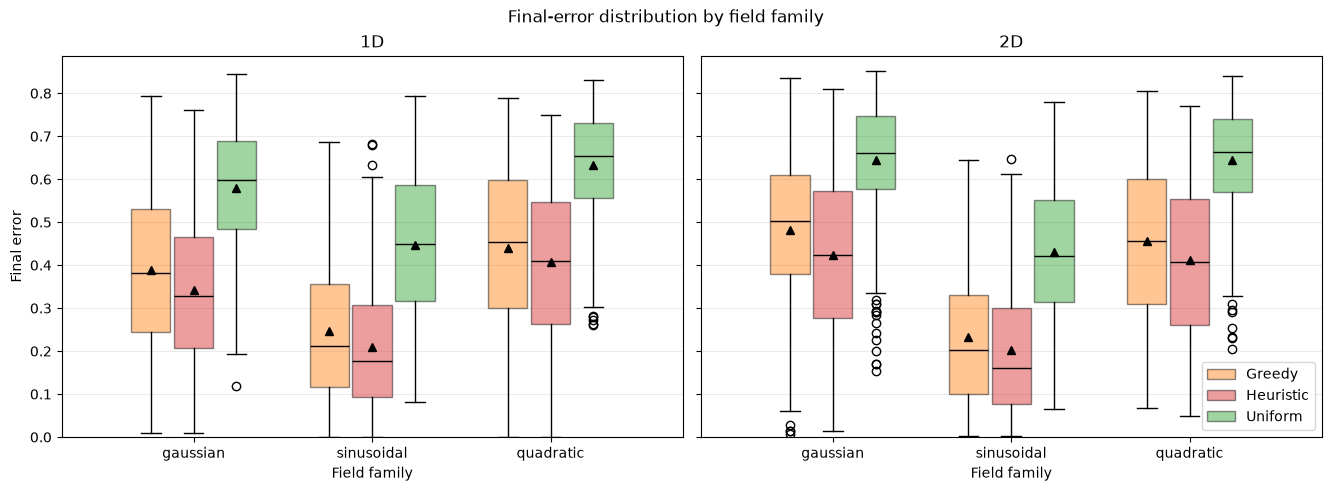

In [36]:
# Reload plotting code so an open kernel does not reuse an older function.
comparison_analysis = importlib.reload(comparison_analysis)
# Load saved records when the expensive run cell was intentionally skipped.
if "records_by_dataset" not in globals():
    records_by_dataset = {
        dataset: comparison_analysis.load_approximate_results(
            dataset, results_root=RESULTS_ROOT, run_scope=RUN_SCOPE
        )
        for dataset in DATASETS
    }
figures = comparison_analysis.make_combined_approximate_plots(
    records_by_dataset,
    results_root=RESULTS_ROOT,
    run_scope=RUN_SCOPE,
)
for title, figure in figures:
    display(Markdown(f"### {title}"))
    display(figure)
    plt.close(figure)

## Saved files

```text
results/algorithm_comparison/
├── benchmark_1d_results_<test|full>/tables/
├── benchmark_2d_results_<test|full>/tables/
└── results_summary_benchmark_1d_benchmark_2d_<test|full>/figures/
```